# Restart the kernel every time you run this
### For some reason
#### Honestly man, just get better at this
##### This can't keep happening

In [1]:
import os
import codecs
import sys
import json
from astropy.io import fits
import numpy as np
import math
from astropy import units as u
from astropy.wcs import WCS
from scipy.ndimage import binary_dilation, generic_filter
import pandas as pd
import matplotlib.pyplot as plt
import pkg_resources
import re
from astropy import constants as ac
from tqdm import tqdm
from scipy import interpolate
import sympy as sp
import seaborn as sns
from pint import UnitRegistry

In [2]:
def get_tau(T_up, T_lo, X_fac,tolerance=1e-2, max_iterations=10):
    guess=-X_fac*np.log(abs((1-T_lo/T_up)))
    tau=guess-((T_up/T_lo*(1-np.exp(-guess/X_fac)))-(1-np.exp(-guess)))/((T_up/T_lo*np.exp(-guess/X_fac)/X_fac)-np.exp(-guess))
    i=0
    while abs(tau-guess) > tolerance and i < max_iterations:
        guess=tau
        tau=guess-((T_up/T_lo*(1-np.exp(-guess/X_fac)))-(1-np.exp(-guess)))/((T_up/T_lo*np.exp(-guess/X_fac)/X_fac)-np.exp(-guess))
        i=i+1
    return tau
# This is the first attempt of the get tau_function. Works with scalars of length 1

def get_einsteinA(filename, J):
    """
    Read the Einstein A coefficient from a LAMDA .dat file
    """
    file = open(filename)
    # read the content of the file opened
    content = file.readlines()
    line = content[J + 50]
    EA = re.split(' +', line)[4]
    return np.float32(EA) / u.s

def get_rms_map(cube):
    """
    Returns t|he RMS map of a cube by inverting the negative pixel values,
    and assuming that the noise is normally distributed around 0.
    """
    values = cube.copy()
    #values[cube > 0] = np.nan This feels wrong
    rms_map = np.sqrt(np.nanmean(values**2, axis=0))
    return rms_map

def binary_dilate_cube(cube, **kwargs):
    """
    Perform a plane-wise binary dilation on a cube
    """
    dilated = np.zeros_like(cube)
    for zz, plane in enumerate(cube):
        dilated[zz] = binary_dilation(plane, **kwargs)
    return dilated

def get_Tex(cube, nu, Tbg=2.7):
    """
    Returns the excitation temperature cube for an emission cube that
    is assumed to be optically thick
    """
    T0 = get_T0(nu)
    Tex = T0 * (np.log(1 + (T0 / 
                (cube + (T0 / (np.exp(T0 / Tbg) - 1))))))**-1
    return Tex

def get_freq(filename, J):
    """
    Read the rest frequency from a LAMDA .dat file
    """
    file = open(filename)
    # read the content of the file opened
    content = file.readlines()
    line = content[J + 50]
    freq = re.split(' +', line)[5]
    return np.float32(freq)*10**9

def get_T0(nu):
    """
    Returns the T_0 quantity (h * nu / k_B) for a particular frequency
    """
    return np.float32(ac.h * nu / ac.k_B)

def fill_cube_rescale(cube1, cube2, **kwargs):
    """
    Fills missing values in cube1 based on values in cube2, and assuming
    that there is a constant scaling relationship between the two
    """
    # cube1_fill = cube1.copy()
    # ratio = np.nanmedian(cube2.value / cube1.value)
    # cube1_fill[np.isnan(cube1)] = cube2[np.isnan(cube1)].value / ratio

    # # Now clean it up with a median filter
    # for i in tqdm(range(np.shape(cube1_fill)[0]), desc='Extrapolating Tau values'):
    #     cube1_fill[i] = generic_filter(cube1_fill[i], 
    #                                         np.nanmedian, **kwargs)
    
    # cube1_fill[np.isnan(cube2)] = np.nan

    ratio = cube2 / cube1
    wmean = np.nansum(ratio * cube2) / np.nansum(cube2)

    rescaled_cube1 = cube2 / wmean

    filled_cube1 = cube1.copy()
    filled_cube1[np.isnan(filled_cube1)] = rescaled_cube1[np.isnan(filled_cube1)]

    return filled_cube1

def fill_cube_interp(cube, emissionmask, **kwargs):
    """
    Interpolate over missing values in each plane of a cube, following:
    https://stackoverflow.com/questions/37662180/interpolate-missing-values-2d-python
    """
    interpolated = cube.copy()

    for pp, plane in enumerate(tqdm(interpolated)):
        if len(np.where(~np.isnan(plane))[0]) >= 4:
            xindices = np.arange(0, plane.shape[1])
            yindices = np.arange(0, plane.shape[0])
            
            #  Mask invalid values
            plane = np.ma.masked_invalid(plane)
            xx, yy = np.meshgrid(xindices, yindices)
            
            # Get only the valid values
            x1 = xx[~plane.mask]
            y1 = yy[~plane.mask]
            newplane = plane[~plane.mask]

            # Perform the interpolation
            newplane = interpolate.griddata((x1, y1), newplane.ravel(),
                                       (xx, yy), **kwargs)  
            
            # Mask to only include values with not-nan value in nanmask cube
            newplane[np.isnan(emissionmask[pp])] = np.nan   
            
            # Assign plane to output cube
            interpolated[pp] = newplane   
    
    return interpolated

In [3]:
def solve_tau_3d(T_up, T_lo, X_fac, tolerance=5e-2, max_iterations=10):
    result = np.zeros_like(T_lo)  # Initialize result array
    
    for i in range(T_lo.shape[0]):
        for j in range(T_lo.shape[1]):
            for k in range(T_lo.shape[2]):
                R=T_up[i, j, k] / T_lo[i, j, k]
                guess = -X_fac * np.log(abs((1 - (T_lo[i, j, k] / T_up[i, j, k]))))
                iteration_count = 0
                t = guess
                while iteration_count < max_iterations:
                    condition = R >= X_fac
                    if condition:
                        result[i, j, k] = np.nan
                        break
                    new_t = t - ((R * (1 - np.exp(-t / X_fac))) - (1 - np.exp(-t))) / (
                            (R * np.exp(-t / X_fac) / X_fac) - np.exp(-t))
                    if abs(new_t - t) <= tolerance:
                        result[i, j, k] = new_t
                        break
                    t = new_t
                    iteration_count += 1
                else:
                    # If max_iterations reached without convergence, handle appropriately
                    pass  # You can add code here for handling non-convergence
    return result

# This is what I got when I asked it to repeat the code for 3D arrays, seems to work but takes its sweet time.

In [15]:
def solve_tau_3d_alt(T_up, T_lo, X_fac, tolerance=5e-2, max_iterations=10):
    result = np.zeros_like(T_lo)  # Initialize result array

    Tup_temp=np.maximum(T_up,T_lo)
    Tlo_temp=np.minimum(T_up, T_lo)
    
    for i in range(T_lo.shape[0]):
        for j in range(T_lo.shape[1]):
            for k in range(T_lo.shape[2]):
                R=Tup_temp[i, j, k] / Tlo_temp[i, j, k]
                guess = -X_fac * np.log(abs((1 - 1/R)))
                iteration_count = 0
                t = guess
                while iteration_count < max_iterations:
                  #  if R>=X_fac:
                     #   result[i, j, k] = np.nan # Not yet Ferb
                     #   break
                    new_t = t - ((R * (1 - np.exp(-t / X_fac))) - (1 - np.exp(-t))) / (
                            (R * np.exp(-t / X_fac) / X_fac) - np.exp(-t))
                    if abs(new_t - t) <= tolerance:
                        result[i, j, k] = new_t
                        break
                    t = new_t
                    iteration_count += 1
                else:
                    # If max_iterations reached without convergence, handle appropriately
                    pass  # You can add code here for handling non-convergence
    return result

In [4]:
params = json.loads(open('parameters.json').read())
data_in_13CO_1 = params['data_in_13CO_1']
data_in_13CO_3 = params['data_in_13CO_3']

hdr_1 = fits.getheader(data_in_13CO_1)
wcs_1 = WCS(hdr_1).celestial
hdr_out_1 = WCS(hdr_1).to_header()
hdr_Tau_1 = hdr_out_1.copy()

hdr_3 = fits.getheader(data_in_13CO_3)
wcs_3 = WCS(hdr_3).celestial
hdr_out_3 = WCS(hdr_3).to_header()
hdr_Tau_3 = hdr_out_3.copy()


global DATA_PATH
trans_3=3
trans_1=1
## To mask the data I needed the get_Tex function, which required these blocks. 17/4 KT

params = json.loads(open('parameters.json').read())
transition_3 = params['transition'+str(trans_3)]
transition_1 = params['transition'+str(trans_1)]
J_up_3, J_lo_3 = np.int32(transition_3.split('-'))
J_up_1, J_lo_1 = np.int32(transition_1.split('-'))

DATA_PATH = pkg_resources.resource_filename('CODLE', 'data/')
nu_12_3 = get_freq(f'{DATA_PATH}/co.dat', J_up_3)
nu_13_3 = get_freq(f'{DATA_PATH}/13co.dat', J_up_3)
nu_18_3 = get_freq(f'{DATA_PATH}/c18o.dat', J_up_3)

nu_12_1 = get_freq(f'{DATA_PATH}/co.dat', J_up_1)
nu_13_1 = get_freq(f'{DATA_PATH}/13co.dat', J_up_1)
nu_18_1 = get_freq(f'{DATA_PATH}/c18o.dat', J_up_1)

T03=get_T0(nu_13_3)
Tbg3=1/(np.exp(T03/2.7)-1)
print(Tbg3)

T01=get_T0(nu_13_1)
Tbg1=1/(np.exp(T01/2.7)-1)
print(Tbg1)
#T_bg32=1/np.exp(get_T0(nu_13_3)

nu_32=nu_13_3
nu_10=nu_13_1
T_bg32=Tbg3
T_bg10=Tbg1

e_0= 8.854187817e-12
k_B=ac.k_B.value
m_12=1.13e-26
m_13=1.19e-26
h=ac.h.value
r=0.113e-9
I13=m_13*r**2
I12=m_12*r**2
B13=h/(8*math.pi**2*I13)
B12=h/(8*math.pi**2*I12)

0.0028133393302115926
0.16417668618463557


In [5]:
# JCMT G37 3-2
CO12_3 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/COHRS_12CO_G037_23arcsec_aligned.fits')
CO13_3 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/CHIMPS_13CO_G037_23arcsec_aligned.fits')
CO18_3 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/C18O/CHIMPS_C18O_G037_23arcsec_aligned.fits')

# MOPRA G330-340 1-0
#CO12 = fits.getdata('G330-340-12CO_giantcube_trim.fit')
#CO13 = fits.getdata('G330-340-13CO_giantcube_trim.fit')
#CO18 = fits.getdata('G330-340-C18O_giantcube_trim.fit')

# FUGIN G37 1-0
CO12_1 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/12CO/FGN_037_12CO_23arcsec_aligned.fits')
CO13_1 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/13CO/FGN_037_13CO_23arcsec_aligned.fits')
CO18_1 = fits.getdata('/Users/kyriakos.trakakis/Downloads/CHIMPS_COHRS/C18O/FGN_037_C18O_23arcsec_aligned.fits')

## SNR TEST

In [6]:
RMS12_1 = get_rms_map(CO12_1)
RMS13_1 = get_rms_map(CO13_1)
RMS18_1 = get_rms_map(CO18_1)

SNR12_1 = CO12_1 / RMS12_1
SNR13_1 = CO13_1 / RMS13_1
SNR18_1 = CO18_1 / RMS18_1

RMS12_3 = get_rms_map(CO12_3)
RMS13_3 = get_rms_map(CO13_3)
RMS18_3 = get_rms_map(CO18_3)

SNR12_3 = CO12_3 / RMS12_3
SNR13_3 = CO13_3 / RMS13_3
SNR18_3 = CO18_3 / RMS18_3

In [7]:
#CO12_SNR = np.zeros_like(CO12)
#CO13_SNR = np.zeros_like(CO13)
#CO18_SNR = np.zeros_like(CO18)

CO12_SNR_1 = CO12_1.copy()
CO13_SNR_1 = CO13_1.copy()
CO18_SNR_1 = CO18_1.copy()

i_1=SNR12_1>3
j_1=SNR13_1>3
k_1=SNR18_1>3


CO12_SNR_1[i_1]=CO12_1[i_1]
CO13_SNR_1[j_1]=CO13_1[j_1]
CO18_SNR_1[k_1]=CO18_1[k_1]

CO12_SNR_1[SNR12_1 < 3] = np.nan
CO13_SNR_1[SNR13_1 < 3] = np.nan
CO18_SNR_1[SNR18_1 < 3] = np.nan # np.nan

#CO12[SNR12 < 3] = np.nan
#CO13[SNR13 < 3] = np.nan
#CO18[SNR18 < 3] = np.nan

CO12_SNR_3 = CO12_3.copy()
CO13_SNR_3 = CO13_3.copy()
CO18_SNR_3 = CO18_3.copy()

i_3=SNR12_3>3
j_3=SNR13_3>3
k_3=SNR18_3>3


CO12_SNR_3[i_3]=CO12_3[i_3]
CO13_SNR_3[j_3]=CO13_3[j_3]
CO18_SNR_3[k_3]=CO18_3[k_3]

CO12_SNR_3[SNR12_3 < 3] = np.nan
CO13_SNR_3[SNR13_3 < 3] = np.nan
CO12_SNR_3[SNR18_3 < 3] = np.nan

In [ ]:
fits.writeto('CO12_SNR.fits', CO12_SNR_old, hdr_Tau, overwrite=True)
#fits.writeto('CO12 SNR.fits', CO12_SNR, hdr_Tau, overwrite=True)
#fits.writeto('CO12 SNR old.fits', CO12_SNR_old, hdr_Tau, overwrite=True)

## Mask test

In [9]:
mask18_13_1 = (1 * CO18_1 > CO13_1)
mask13_12_1= (1 * CO13_1 > CO12_1)
mask18_12_1= (1 * CO18_1 > CO12_1)
dilated_mask18_13_1 = binary_dilate_cube(mask18_13_1, iterations=1)
dilated_mask18_12_1 = binary_dilate_cube(mask18_12_1, iterations=1)
dilated_mask13_12_1 = binary_dilate_cube(mask13_12_1, iterations=1)

mask18_13_3 = (1 * CO18_3 > CO13_3)
mask13_12_3= (1 * CO13_3 > CO12_3)
mask18_12_3= (1 * CO18_3 > CO12_3)
dilated_mask18_13_3 = binary_dilate_cube(mask18_13_3, iterations=1)
dilated_mask18_12_3 = binary_dilate_cube(mask18_12_3, iterations=1)
dilated_mask13_12_3 = binary_dilate_cube(mask13_12_3, iterations=1)

In [ ]:
CO12_mask=CO12.copy()
ratio=np.zeros_like(CO12)
ratio=CO12_SNR_old/CO18_SNR_old
CO12_mask[dilated_mask13_12 == 1] = np.nan
#ratio[mask13_12]=10

In [ ]:
#fits.writeto('CO12.fits', CO12, hdr_Tau, overwrite=True)
#fits.writeto('CO12 mask.fits', CO12_mask, hdr_Tau, overwrite=True)
fits.writeto('CO12_18 ratio SNR3.fits', ratio, hdr_Tau, overwrite=True)

In [8]:
np.shape(CO18_SNR_3)

(385, 601, 1201)

In [16]:
import time


start_time = time.time()
Tau_13_18_1 = solve_tau_3d_alt(CO13_SNR_1,CO18_SNR_1,6.5)
end_time = time.time()
# Time the execution
elapsed_time = end_time - start_time
print("Elapsed time:", elapsed_time/60, "minutes")

start_time = time.time()
Tau_13_18_3 = solve_tau_3d_alt(CO13_SNR_3,CO18_SNR_3,6.5)
end_time = time.time()
# Time the execution
elapsed_time = end_time - start_time
print("Elapsed time:", elapsed_time/60, "minutes")


Elapsed time: 123.63616909980774 minutes


In [39]:
#Tau_13_18_1_copy=Tau_13_18_1.copy()
#Tau_13_18_1_copy[dilated_mask13_12_1 == 1] = np.nan

Tau_12_13_3_copy=Tau_12_13_3.copy()
Tau_12_13_3_copy[dilated_mask13_12_3 == 1] = np.nan

In [17]:
fits.writeto('CODLE_FUGIN_G037_Tau1318_SNR3_23arcsec_aligned.fits', Tau_13_18_1, hdr_Tau_1, overwrite=True)
fits.writeto('CODLE_COHRS_G037_Tau1318_SNR3_23arcsec_aligned.fits', Tau_13_18_3, hdr_Tau_3, overwrite=True)

In [ ]:
#Tau_13_18_fill = fill_cube_rescale(Tau_13_18_copy, CO13, size=3) # Original
#Tau_12_13_fill = fill_cube_rescale(Tau_12_13_copy, CO12, size=3) # KT
Tau_13_18_fill = fill_cube_interp(Tau_13_18, CO12, method="linear")

In [ ]:
fits.writeto('CODLE_G35_1_0_1318_R65_SNR3_1312masked_smoothed_interp_2kms_alt.fits', Tau_13_18_fill, hdr_Tau, overwrite=True)

In [ ]:
Tau_13_18_G35_1_0=Tau_13_18.copy()

In [ ]:
def solve Tex(Tup, Tlo, tau1, tau2, v1, v2, tolerance=5e-2, max_iterations=10):
    result = np.zeros_like(T_lo)  # Initialize result array

    Tup_temp=np.zeros_like(T_lo)
    Tlo_temp=np.zeros_like(T_lo)

## Tex Part

In [6]:
tau_eq=R-(1-sp.exp(-tau_32))/(1-sp.exp(-tau_32/X_fac))
tau_eq

tau_dif=sp.diff(tau_eq,tau_32)
tau_dif

tau_func=tau_eq/tau_dif
tau_func

NameError: name 'R' is not defined

In [8]:
# Define the symbols
R, T_b32, T_b10, tau_32, tau_10, nu_32, nu_10, T_bg32, T_bg10, T_ex, X_fac = sp.symbols('R T_b32 T_b10 tau_32 tau_10 nu_32 nu_10 T_bg32 T_bg10 T_ex X_fac')
h, k_B = sp.symbols('h k_B')

# Define the function based on the equation
lhs = R * ((1 - sp.exp(-tau_10)) * nu_10 / (sp.exp(h * nu_10 / (k_B * T_ex)) - 1) - T_bg10)
rhs = (1 - sp.exp(-tau_32)) * nu_32 / (sp.exp(h * nu_32 / (k_B * T_ex)) - 1) - T_bg32

# Define the equation
equation = R-(1-sp.exp(-tau_32))/(1-sp.exp(-tau_10))*nu_32/nu_10*((sp.exp(h*nu_32/k_B/T_ex)-1)**(-1)-T_bg32)/(((sp.exp(h*nu_10/k_B/T_ex)-1)**(-1)-T_bg10))

# Calculate the derivative with respect to T_ex
derivative = sp.diff(equation, T_ex)

derivative

h*nu_32*(1 - exp(-tau_32))*(-T_bg32 + 1/(exp(h*nu_32/(T_ex*k_B)) - 1))*exp(h*nu_10/(T_ex*k_B))/(T_ex**2*k_B*(1 - exp(-tau_10))*(-T_bg10 + 1/(exp(h*nu_10/(T_ex*k_B)) - 1))**2*(exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - exp(-tau_32))*exp(h*nu_32/(T_ex*k_B))/(T_ex**2*k_B*nu_10*(1 - exp(-tau_10))*(-T_bg10 + 1/(exp(h*nu_10/(T_ex*k_B)) - 1))*(exp(h*nu_32/(T_ex*k_B)) - 1)**2)

In [9]:
fraction=T_ex-equation/derivative
fraction

T_ex - (R - nu_32*(1 - exp(-tau_32))*(-T_bg32 + 1/(exp(h*nu_32/(T_ex*k_B)) - 1))/(nu_10*(1 - exp(-tau_10))*(-T_bg10 + 1/(exp(h*nu_10/(T_ex*k_B)) - 1))))/(h*nu_32*(1 - exp(-tau_32))*(-T_bg32 + 1/(exp(h*nu_32/(T_ex*k_B)) - 1))*exp(h*nu_10/(T_ex*k_B))/(T_ex**2*k_B*(1 - exp(-tau_10))*(-T_bg10 + 1/(exp(h*nu_10/(T_ex*k_B)) - 1))**2*(exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - exp(-tau_32))*exp(h*nu_32/(T_ex*k_B))/(T_ex**2*k_B*nu_10*(1 - exp(-tau_10))*(-T_bg10 + 1/(exp(h*nu_10/(T_ex*k_B)) - 1))*(exp(h*nu_32/(T_ex*k_B)) - 1)**2))

In [18]:
def solve_Tex(T_up, T_lo, tau_32, tau_10, tol=5e-2, max_iterations=10):
    result = np.zeros_like(T_lo)  # Initialize result array
    h=ac.h.value
    k_B=ac.k_B.value
    c=ac.c.value
    # Define frequencies and background temperatures.
    nu_32=nu_13_3
    nu_10=nu_13_1
    T_bg32=Tbg3
    T_bg10=Tbg1
    
    for i in range(result.shape[0]):
        for j in range(result.shape[1]):
            for k in range(result.shape[2]):
                R=T_up[i, j, k] / T_lo[i, j, k]
                T_ex = 5
                iteration_count=0
                if T_up[i,j,k]<=T_lo[i,j,k]:
                   R=1/R
                while iteration_count < max_iterations:
                    new_Tex =T_ex - (R - nu_32*(1 - np.exp(-tau_32[i,j,k]))*(-T_bg32 + (np.exp(h*nu_32/(k_B*T_ex)) - 1)**(-1.0))/(nu_10*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))))/(h*nu_32*(1 - np.exp(-tau_32[i,j,k]))*(-T_bg32 + (np.exp(h*nu_32/(T_ex*k_B)) - 1)**(-1.0))*np.exp(h*nu_10/(T_ex*k_B))/(T_ex*T_ex*k_B*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))**2*(np.exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - np.exp(-tau_32[i,j,k]))*np.exp(h*nu_32/(T_ex*k_B))/(T_ex*T_ex*k_B*nu_10*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))*(np.exp(h*nu_32/(T_ex*k_B)) - 1)**2))
                    if abs(new_Tex - T_ex) <= tol:
                        result[i, j, k] = new_Tex
                        break
                    T_ex = new_Tex
                    iteration_count += 1
    return result

In [ ]:
new_Tex =T_ex - (R - nu_32*(1 - sp.exp(-tau_32))*(-T_bg32 + (sp.exp(h*nu_32/(k_B*T_ex)) - 1)**(-1.0))/(nu_10*(1 - sp.exp(-tau_10))*(-T_bg10 + (sp.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))))/(h*nu_32*(1 - sp.exp(-tau_32))*(-T_bg32 + (sp.exp(h*nu_32/(T_ex*k_B)) - 1)**(-1.0))*sp.exp(h*nu_10/(T_ex*k_B))/(T_ex*T_ex*k_B*(1 - sp.exp(-tau_10))*(-T_bg10 + (sp.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))**2*(sp.exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - sp.exp(-tau_32))*sp.exp(h*nu_32/(T_ex*k_B))/(T_ex*T_ex*k_B*nu_10*(1 - sp.exp(-tau_10))*(-T_bg10 + (sp.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))*(sp.exp(h*nu_32/(T_ex*k_B)) - 1)**2))
new_Tex

In [19]:
start_time = time.time()
tex_test=solve_Tex(CO13_SNR_3,CO13_SNR_1, Tau_13_18_3, Tau_13_18_1)
end_time = time.time()
# Time the execution
elapsed_time = end_time - start_time
print("Elapsed time:", elapsed_time/60, "minutes")

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/528297451.py:21: RuntimeWarning: invalid value encountered in scalar divide
  new_Tex =T_ex - (R - nu_32*(1 - np.exp(-tau_32[i,j,k]))*(-T_bg32 + (np.exp(h*nu_32/(k_B*T_ex)) - 1)**(-1.0))/(nu_10*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))))/(h*nu_32*(1 - np.exp(-tau_32[i,j,k]))*(-T_bg32 + (np.exp(h*nu_32/(T_ex*k_B)) - 1)**(-1.0))*np.exp(h*nu_10/(T_ex*k_B))/(T_ex*T_ex*k_B*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))**2*(np.exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - np.exp(-tau_32[i,j,k]))*np.exp(h*nu_32/(T_ex*k_B))/(T_ex*T_ex*k_B*nu_10*(1 - np.exp(-tau_10[i,j,k]))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))*(np.exp(h*nu_32/(T_ex*k_B)) - 1)**2))
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/528297451.py:21: RuntimeWarning: divide by zero encountered in scalar divide
  new_Tex =T_ex - (R - nu_32*(1 - np.exp(-tau_32[i

Elapsed time: 2765.937066380183 minutes


In [23]:
def solve_Tex_1D(T_up, T_lo, tau_32, tau_10, tol=5e-2, max_iterations=10):
    result = np.zeros_like(T_lo)  # Initialize result array
    h=ac.h.value
    k_B=ac.k_B.value
    c=ac.c.value
    R=T_lo/T_up
    # Define frequencies and background temperatures.
    nu_32=nu_13_3
    nu_10=nu_13_1
    T_bg32=Tbg3
    T_bg10=Tbg1
    T_ex=5
    new_Tex =T_ex - (R - nu_32*(1 - np.exp(-tau_32))*(-T_bg32 + (np.exp(h*nu_32/(k_B*T_ex)) - 1)**(-1.0))/(nu_10*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))))/(h*nu_32*(1 - np.exp(-tau_32))*(-T_bg32 + (np.exp(h*nu_32/(T_ex*k_B)) - 1)**(-1.0))*np.exp(h*nu_10/(T_ex*k_B))/(T_ex*T_ex*k_B*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))**2*(np.exp(h*nu_10/(T_ex*k_B)) - 1)**2) - h*nu_32**2*(1 - np.exp(-tau_32))*np.exp(h*nu_32/(T_ex*k_B))/(T_ex*T_ex*k_B*nu_10*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/(T_ex*k_B)) - 1)**(-1.0))*(np.exp(h*nu_32/(T_ex*k_B)) - 1)**2))
    return new_Tex

In [38]:
tex_test_1D=solve_Tex_1D(CO13_SNR_3[68,104,234],CO13_SNR_1[68,104,234],Tau_13_18_3[68,104,234],Tau_13_18_1[68,104,234])

In [139]:
CO13_SNR_1.shape

(100, 474, 237)

In [140]:
CO13_SNR_3.shape

(100, 474, 237)

In [141]:
Tau_13_18_3.shape

(100, 474, 237)

In [142]:
Tau_13_18_1.shape

(100, 474, 237)

In [275]:
tex_test.shape

(100, 474, 237)

In [20]:
fits.writeto('CODLE_Tex_COHRS_FUGIN_G037_32_10_CO13_SNR3_23arcsec_aligned.fits', tex_test, hdr_Tau_3, overwrite=True)

## Decoding Excitation Temperature

In [39]:
tex_test_1D

22.71610042938233

In [24]:
h=ac.h.value
k_B=ac.k_B.value
# Define frequencies and background temperatures.
R=(3.5739834/1.8547696)
nu_32=nu_13_3
nu_10=nu_13_1
T_bg32=Tbg3
T_bg10=Tbg1
tau_32=Tau_13_18_3[68,104,234]
tau_10=Tau_13_18_1[68,104,234]
T_ex=5

NameError: name 'Tau_13_18_3' is not defined

In [69]:
Full_eq_1D =T_ex - (R - nu_32*(1 - np.exp(-tau_32))*(-T_bg32 + (np.exp(h*nu_32/k_B/T_ex) - 1)**(-1.0))/(nu_10*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/k_B/T_ex) - 1)**(-1.0))))/(h*nu_32*(1 - np.exp(-tau_32))*(-T_bg32 + (np.exp(h*nu_32/k_B/T_ex) - 1)**(-1.0))*np.exp(h*nu_10/k_B/T_ex)/(T_ex*T_ex*k_B*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/k_B/T_ex) - 1)**(-1.0))**2*(np.exp(h*nu_10/k_B/T_ex) - 1)**2) - (h*nu_32**2)*(1 - np.exp(-tau_32))*np.exp(h*nu_32/k_B/T_ex)/(T_ex*T_ex*k_B*nu_10*(1 - np.exp(-tau_10))*(-T_bg10 + (np.exp(h*nu_10/k_B/T_ex) - 1)**(-1.0))*(np.exp(h*nu_32/k_B/T_ex) - 1)**2))

Full_eq_1D

32.488424678979285

In [478]:
CO13_SNR_3[68,104,234]

1.8547696

In [479]:
CO13_SNR_1[68,104,234]

3.5739834

In [59]:
solve_Tex_1D(1.8547696,3.5739834,4.854746,2.2970607)

22.716100036270806

In [58]:
Tau_13_18_3[68,104,234]
#Tau_13_18_1[68,104,234]

4.854746

## Simple Density Method

In [169]:
tau13=fits.getdata('G35_test.fit')
hdr_tau13 = fits.getheader('G35_test.fit')
wcs_tau13 = WCS(hdr_tau13).celestial
hdr_out_tau13 = WCS(hdr_tau13).to_header()

Set OBSGEO-B to    19.822799 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to    19.822799 from OBSGEO-[XYZ].
Set OBSGEO-H to     4117.025 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


In [111]:
T_ex=20
B=5.51e10
c=ac.c.value
A32=get_einsteinA(f'{DATA_PATH}/13co.dat', J_up_3).value
C=8*math.pi/7/c**2*k_B*T_ex/h/B*nu_32**2/A32*np.exp(6*h*B/k_B/T_ex)*(1-np.exp(-h*nu_32/k_B/T_ex))**(-1)

In [171]:
N13=C*tau13

In [71]:
N13

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [76]:
fits.writeto('King_Density_G35_32_C013_SNR3_.fits', N13, hdr_out_tau13, overwrite=True)

In [66]:
CO13_SNR_3[68,104,234]/CO13_SNR_1[68,104,234]

0.306434

In [65]:
tex_test[68,104,234]

0.0

## Column Density

In [21]:
T03

15.86572

In [28]:
# This is for 13CO J=3-2
j=3
i=2

C_13=3*e_0*k_B/(2*math.pi**2*nu_32*j*m_13**2)
C_12=3*e_0*k_B/(2*math.pi**2*nu_32*j*m_12**2)
Z13=k_B/h/B13*(tex_test+h*B13/3/k_B)
#Z12=k_B/h/B12*(tex_test_12+h*B12/3/k_B)


Tbg_ex32=T03/tex_test
#Tbg_ex32_12=T03/tex_test_12
#Tbg_ex32[Tbg_ex32 == np.inf] = np.nan
#Tbg_ex32[Tbg_ex32 == -np.inf] = np.nan

exp1=(1-np.exp(-Tbg_ex32))**(-1)
#exp1_12=(1-np.exp(-Tbg_ex32_12))**(-1)
#exp1[exp1 == np.inf] = np.nan
#exp1[exp1 == -np.inf] = np.nan

exp2=(1/(np.exp(Tbg_ex32)-1)-Tbg3)**(-1)
#exp2_12=(1/(np.exp(Tbg_ex32_12)-1)-Tbg3)**(-1)
#exp2[exp2 == np.inf] = np.nan
#exp2[exp2 == -np.inf] = np.nan

tau_frac=Tau_13_18_3/(1-np.exp(-Tau_13_18_3))
#tau_frac_12=Tau_12_13_3/(1-np.exp(-Tau_12_13_3))
#tau_frac[tau_frac == np.inf] = np.nan
#tau_frac[tau_frac == -np.inf] = np.nan

Tb_int_13 = fits.getdata('FGN_037_13CO_23arcsec_aligned_integ.fits')
Tb_int_12 = fits.getdata('FGN_037_13CO_23arcsec_aligned_integ.fits')

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/1702588352.py:13: RuntimeWarning: divide by zero encountered in divide
  Tbg_ex10=T03/tex_test
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/1702588352.py:23: RuntimeWarning: overflow encountered in exp
  exp2=(1/(np.exp(Tbg_ex10)-1)-Tbg1)**(-1)
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/1702588352.py:28: RuntimeWarning: invalid value encountered in divide
  tau_frac=Tau_13_18_1/(1-np.exp(-Tau_13_18_1))


In [29]:
N32=C_13*Z13*np.exp(h*B13*i*(i+1)/k_B/tex_test)*exp1*exp2*tau_frac*Tb_int_13
#N32[N32<0]=np.nan

#N32_12=C_12*Z12*np.exp(h*B12*i*(i+1)/k_B/tex_test_12)*exp1_12*exp2_12*tau_frac_12*Tb_int_12
#N32_12[N32_12<0]=np.nan

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_33419/218864662.py:1: RuntimeWarning: invalid value encountered in divide
  N32=C_13*Z13*np.exp(h*B13*i*(i+1)/k_B/tex_test)*exp1*exp2*tau_frac*Tb_int_13


In [30]:
#fits.writeto('CODLE_N12CO_COHRS_FUGIN_G35_32_10_SNR3_25arcsec.fits', N32_12, hdr_Tau_3, overwrite=True)
fits.writeto('CODLE_N13_COHRS_FUGIN_G037_32_10_CO13_SNR3_23arcsec_aligned.fits', N32, hdr_Tau_3, overwrite=True)

In [64]:
tex_test.max()

377.3365

In [21]:
def integrate(cube):
    d1=cube.shape[0]
    d2=cube.shape[1]
    d3=cube.shape[2]
    result=np.zeros((d2,d3))
    for i in range(d3):
        for j in range(d2):
            sum=0
            for k in range(d1):
                sum+=cube[k,j,i]
            result[j,i]=sum*2
    return result

In [26]:
integ=integrate(tex_test)

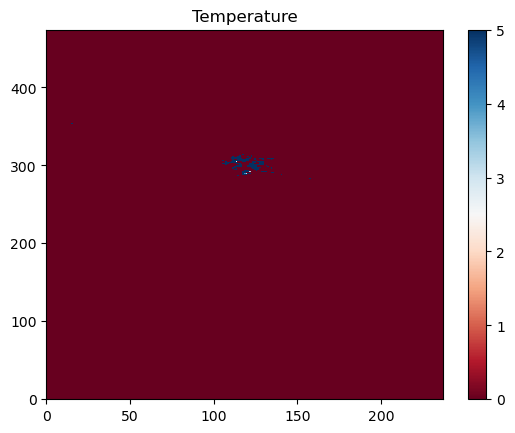

In [27]:
fig, ax = plt.subplots()

c = ax.pcolormesh(integ, cmap='RdBu', vmin=0, vmax=5)
ax.set_title('Temperature')
# set the limits of the plot to the limits of the data
fig.colorbar(c, ax=ax)

In [57]:
integ.max()

754.6729736328125

In [117]:
np.nanmax(N32[N32 != np.inf])

600186600000.0

In [172]:
colte_N13=fits.getdata('colte_COHRS_G35_J32_N13CO_collapsed.fit')
colte_1d=np.ndarray.flatten(colte_N13)
King_1d=np.ndarray.flatten(N13)

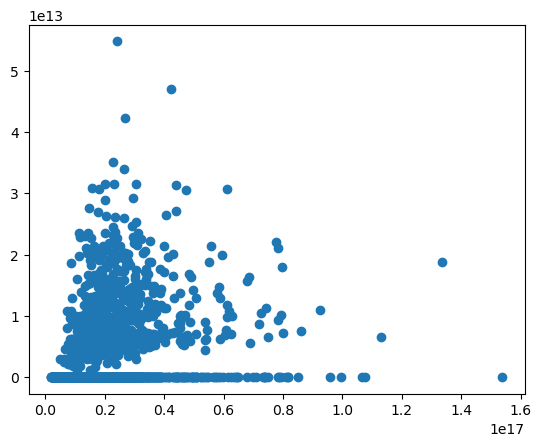

In [181]:
plt.plot(colte_1d, King_1d, 'o')

In [177]:
np.shape(colte_N13)

(474, 237)

In [178]:
np.shape(N13)

(474, 237)

In [109]:
N32[46][294][124].unit

AttributeError: 'numpy.float32' object has no attribute 'unit'

In [97]:
N32.shape

(100, 474, 237)

In [108]:
sol.unit

Unit("m / s")

In [115]:
A32=get_einsteinA(f'{DATA_PATH}/13co.dat', J_up_3).value 55
A32

2.181e-06

# Masking

In [3]:
base_dir='/Users/kyriakos.trakakis/CODLE'

In [25]:
subfolder = "Raf_masks"
if not os.path.exists(subfolder):
    os.makedirs(subfolder)

file_path_write = os.path.join(os.getcwd(),subfolder)
os.chdir(file_path_write)
#Add this at the end of what you do
#os.chdir(base_dir)

In [80]:
CO12_3 = fits.getdata('COHRS_12CO_G35_trim_399_2kms_25arcsec_Rafmasked_aligned.fit')
CO13_3 = fits.getdata('CHIMPS_13CO_G35_trim_399_2kms_25arcsec_Rafmasked_aligned.fit')
CO18_3 = fits.getdata('CHIMPS_C18O_G35_2kms_25arcsec_Rafmasked.fit')

In [87]:
import time

start_time = time.time()
Tau_13_18_3 = solve_tau_3d_alt(CO13_3,CO18_3,6.5)
end_time = time.time()
# Time the execution
elapsed_time = end_time - start_time

print("Elapsed time:", elapsed_time/60, "minutes")

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_47174/993074488.py:10: RuntimeWarning: invalid value encountered in scalar divide
  R=Tup_temp[i, j, k] / Tlo_temp[i, j, k]
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_47174/993074488.py:10: RuntimeWarning: divide by zero encountered in scalar divide
  R=Tup_temp[i, j, k] / Tlo_temp[i, j, k]
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_47174/993074488.py:18: RuntimeWarning: invalid value encountered in scalar multiply
  new_t = t - ((R * (1 - np.exp(-t / X_fac))) - (1 - np.exp(-t))) / (
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_47174/993074488.py:11: RuntimeWarning: divide by zero encountered in divide
  guess = -X_fac * np.log(abs((1 - 1/R)))
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_47174/993074488.py:19: RuntimeWarning: invalid value encountered in scalar multiply
  (R * np.exp(-t / X_fac) / X_fac) - np.exp(-t))
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ip

Elapsed time: 4.474268599351247 minutes


In [88]:
fits.writeto('CODLE_COHRS_G35_J32_Tau1318_R85_SNR3_RAFmask_RatioNAN_2kms_25arcsec_alt.fits', Tau_13_18_3, hdr_Tau_3, overwrite=True)

In [28]:
os.chdir(base_dir)

In [30]:
pwd

'/Users/kyriakos.trakakis/CODLE/Raf masks'

In [65]:
np.shape(CO18_SNR_3)

(100, 473, 237)

In [46]:
zer=[0]
np.append(CO18_SNR_3,zer)

array([nan, nan, nan, ..., nan, nan,  0.])

# Trying to code up Michael's simpler N13 approach from 2013

In [31]:
data_in_12CO = "/Users/kyriakos.trakakis/Downloads/G330-340-12CO_giantcube_trimmed.fits"
data_in_13CO = "/Users/kyriakos.trakakis/Downloads/G330-340-13CO_giantcube_trimmed.fits"
data_in_C18O = "/Users/kyriakos.trakakis/Downloads/G330-340-C18O_giantcube_trimmed.fits"

In [32]:
with fits.open(data_in_12CO) as hdul_12:
    data_12 = hdul_12[0].data
    header_12 = hdul_12[0].header

with fits.open(data_in_13CO) as hdul_13:
    data_13 = hdul_13[0].data
    header_13 = hdul_13[0].header

with fits.open(data_in_C18O) as hdul_18:
    data_18 = hdul_18[0].data
    header_18 = hdul_18[0].header

In [33]:
data_12[np.isnan(data_12)] = 1e-8
data_13[np.isnan(data_13)] = 1e-8
data_18[np.isnan(data_18)] = 1e-8

In [34]:
R13_18 = 8.5

tau_12 = R13_18 * data_13 / data_12
tau_13 = tau_12 / R13_18

In [35]:
dV  = header_12['CDELT3']
pi  = np.pi
k   = ac.k_B
h   = ac.h
c   = ac.c
v12 = 115.27 * u.GHz
v13 = 110.20 * u.GHz
A13 = 6.294E-08 * u.s ** (-1)
A12 = 7.203e-08 * u.s ** (-1)

In [36]:
N12 = data_12 * dV * 8 * pi * k * v12 **2 * tau_12 / (A12 * h * c **3 * (1 - np.exp(-tau_12))) 
N13 = data_13 * dV * 8 * pi * k * v13 **2 * tau_13 / (A13 * h * c **3 * (1 - np.exp(-tau_13))) 

/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_96028/2230119913.py:1: RuntimeWarning: overflow encountered in exp
  N12 = data_12 * dV * 8 * pi * k * v12 **2 * tau_12 / (A12 * h * c **3 * (1 - np.exp(-tau_12)))
/var/folders/my/spqrhq7n74bcr2n7xfhc9hhr0000gp/T/ipykernel_96028/2230119913.py:2: RuntimeWarning: overflow encountered in exp
  N13 = data_13 * dV * 8 * pi * k * v13 **2 * tau_13 / (A13 * h * c **3 * (1 - np.exp(-tau_13)))


In [41]:
fits.writeto('Mopra_G333_region_N13CO_MGB_simple.fits', N13.value, header_13, overwrite=True)
fits.writeto('Mopra_G333_region_N12CO_MGB_simple.fits', N12.value, header_12, overwrite=True)
fits.writeto('Mopra_G333_region_Tau13CO_MGB_simple.fits', tau_13, header_13, overwrite=True)